In [4]:
# Section 1: Imports and Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight


from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
#Section 2: Configuration and Hyperparameters

class Config:

    """Configuration class for hyperparameters and paths"""
    # Paths
    DATASET_ROOT = "/content/drive/MyDrive/datasets/FER-2023 Dataset"
    TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
    TEST_DIR = os.path.join(DATASET_ROOT, "test")
    MODEL_SAVE_PATH = "/content/drive/MyDrive/models/"

    # Image parameters
    IMG_SIZE = 48
    IMG_CHANNELS = 1  # Grayscale
    NUM_CLASSES = 7

    # Training hyperparameters
    BATCH_SIZE = 64
    EPOCHS = 50
    LEARNING_RATE = 0.001
    VALIDATION_SPLIT = 0.2

    # Data augmentation
    ROTATION_RANGE = 20
    WIDTH_SHIFT_RANGE = 0.2
    HEIGHT_SHIFT_RANGE = 0.2
    HORIZONTAL_FLIP = True
    ZOOM_RANGE = 0.2

    # Emotion labels
    EMOTIONS = {
        0: "Angry",
        1: "Disgust",
        2: "Fear",
        3: "Happy",
        4: "Neutral",
        5: "Sad",
        6: "Surprise"
    }

config = Config()

# Create model directory if it doesn't exist
os.makedirs(config.MODEL_SAVE_PATH, exist_ok=True)

print("Configuration loaded successfully!")
print(f"Image Size: {config.IMG_SIZE}x{config.IMG_SIZE}")
print(f"Batch Size: {config.BATCH_SIZE}")
print(f"Epochs: {config.EPOCHS}")

Configuration loaded successfully!
Image Size: 48x48
Batch Size: 64
Epochs: 50


In [6]:
#Section 3: Data Loading and PreProcessing

def load_dataset(directory, img_size=48):
    """Load dataset from directory with proper preprocessing"""
    images = []
    labels = []
    class_names = sorted(os.listdir(directory))
    class_map = {name: idx for idx, name in enumerate(class_names)}

    print(f"\nLoading data from {directory}...")

    for emotion_name in tqdm(class_names, desc="Loading classes"):
        emotion_path = os.path.join(directory, emotion_name)
        if not os.path.isdir(emotion_path):
            continue

        label = class_map[emotion_name]

        for img_file in os.listdir(emotion_path):
            img_path = os.path.join(emotion_path, img_file)
            try:
                # Load and preprocess image
                img = tf.keras.preprocessing.image.load_img(
                    img_path,
                    color_mode='grayscale',
                    target_size=(img_size, img_size)
                )
                img_array = tf.keras.preprocessing.image.img_to_array(img)
                img_array = img_array / 255.0  # Normalize

                images.append(img_array)
                labels.append(label)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")
                continue

    return np.array(images), np.array(labels), class_map

# Load training and test data
print("="*70)
print("LOADING DATASET")
print("="*70)

X_train_full, y_train_full, class_map = load_dataset(config.TRAIN_DIR, config.IMG_SIZE)
X_test, y_test, _ = load_dataset(config.TEST_DIR, config.IMG_SIZE)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=config.VALIDATION_SPLIT,
    random_state=42,
    stratify=y_train_full
)

print(f"\nDataset Statistics:")
print(f"Training samples: {X_train.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Image shape: {X_train.shape[1:]}")
print(f"Number of classes: {config.NUM_CLASSES}")

# Calculate class distribution
unique, counts = np.unique(y_train, return_counts=True)
class_distribution = dict(zip(unique, counts))
print("\nClass Distribution in Training Set:")
for class_id, count in class_distribution.items():
    emotion = list(class_map.keys())[class_id]
    print(f"{emotion}: {count} ({count/len(y_train)*100:.2f}%)")

LOADING DATASET

Loading data from /content/drive/MyDrive/datasets/FER-2023 Dataset/train...


Loading classes: 100%|██████████| 7/7 [16:47<00:00, 143.86s/it]



Loading data from /content/drive/MyDrive/datasets/FER-2023 Dataset/test...


Loading classes: 100%|██████████| 7/7 [03:48<00:00, 32.65s/it]


Dataset Statistics:
Training samples: 22967
Validation samples: 5742
Test samples: 7178
Image shape: (48, 48, 1)
Number of classes: 7

Class Distribution in Training Set:
angry: 3196 (13.92%)
disgust: 349 (1.52%)
fear: 3277 (14.27%)
happy: 5772 (25.13%)
neutral: 3972 (17.29%)
sad: 3864 (16.82%)
surprise: 2537 (11.05%)


In [7]:
#Section 4: Data Augmentation

#Calculate class weights for imbalanced dataset
class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

print("\nClass Weights for Imbalanced Data:")
for class_id, weight in class_weight_dict.items():
    emotion = list(class_map.keys())[class_id]
    print(f"{emotion}: {weight:.2f}")

# Data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=config.ROTATION_RANGE,
    width_shift_range=config.WIDTH_SHIFT_RANGE,
    height_shift_range=config.HEIGHT_SHIFT_RANGE,
    horizontal_flip=config.HORIZONTAL_FLIP,
    zoom_range=config.ZOOM_RANGE,
    fill_mode='nearest'
)

# No augmentation for validation and test
val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

print("\nData augmentation configured successfully!")


Class Weights for Imbalanced Data:
angry: 1.03
disgust: 9.40
fear: 1.00
happy: 0.57
neutral: 0.83
sad: 0.85
surprise: 1.29

Data augmentation configured successfully!


In [8]:
#Section 5: Model Architetcture - CNN

def create_custom_cnn(input_shape=(48, 48, 1), num_classes=7):
    """Custom CNN architecture with batch normalization and dropout"""
    model = models.Sequential([
        # Block 1
        layers.Conv2D(64, (3, 3), padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Block 3
        layers.Conv2D(256, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(256, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Block 4
        layers.Conv2D(512, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(512, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Fully connected layers
        layers.Flatten(),
        layers.Dense(512),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.5),

        layers.Dense(256),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.5),

        # Output layer
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

In [9]:
#Section 6: Model Architecture - Transfer Learning (VGG16)

def create_transfer_learning_model(input_shape=(48, 48, 3), num_classes=7):
    """Transfer learning model using VGG16 as base"""
    # Load pre-trained VGG16 without top layers
    base_model = VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    # Freeze base model layers
    for layer in base_model.layers:
        layer.trainable = False

    # Add custom top layers
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

In [10]:
#Section 7: Model Training Setup

def compile_model(model, learning_rate=0.001):
    """Compile model with optimizer, loss, and metrics"""
    optimizer = optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Create callbacks
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(
    os.path.join(config.MODEL_SAVE_PATH, 'best_model.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

tensorboard = callbacks.TensorBoard(
    log_dir='./logs',
    histogram_freq=1
)

callback_list = [early_stopping, reduce_lr, checkpoint, tensorboard]

In [11]:
#Section 8: Train Custom CNN Model

print("\n" + "="*70)
print("TRAINING CUSTOM CNN MODEL")
print("="*70)

# Create and compile model
cnn_model = create_custom_cnn(
    input_shape=(config.IMG_SIZE, config.IMG_SIZE, config.IMG_CHANNELS),
    num_classes=config.NUM_CLASSES
)

cnn_model = compile_model(cnn_model, config.LEARNING_RATE)

# Print model summary
print("\nModel Architecture:")
cnn_model.summary()

# Training model
history_cnn = cnn_model.fit(
    train_datagen.flow(X_train, y_train, batch_size=config.BATCH_SIZE),
    validation_data=(X_val, y_val),
    epochs=config.EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callback_list,
    verbose=1
)

# Saving
cnn_model.save(os.path.join(config.MODEL_SAVE_PATH, 'custom_cnn_final.h5'))
print("\nModel saved successfully!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



TRAINING CUSTOM CNN MODEL

Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 12, 12, 256)    │             

 Total params: 7,187,911 (27.42 MB)

 Trainable params: 7,182,535 (27.40 MB)

... (21 outputs left out)

359/359 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.6140 - loss: 0.9859 - val_accuracy: 0.6252 - val_loss: 0.9873 - learning_rate: 5.0000e-04
Epoch 45/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6094 - loss: 0.9945
Epoch 45: val_accuracy improved from 0.62522 to 0.62731, saving model to /content/drive/MyDrive/models/best_model.h5


359/359 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.6094 - loss: 0.9946 - val_accuracy: 0.6273 - val_loss: 1.0033 - learning_rate: 5.0000e-04
Epoch 46/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6174 - loss: 0.9652
Epoch 46: val_accuracy did not improve from 0.62731
359/359 ━━━━━━━━━━━━━━━━━━━━ 24s 67ms/step - accuracy: 0.6174 - loss: 0.9653 - val_accuracy: 0.6083 - val_loss: 1.0467 - learning_rate: 5.0000e-04
Epoch 47/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6039 - loss: 0.9980
Epoch 47: val_accuracy did not improve from 0.62731
359/359 ━━━━━━━━━━━━━━━━━━━━ 23s 63ms/step - accuracy: 0.6039 - loss: 0.9980 - val_accuracy: 0.6001 - val_loss: 1.0289 - learning_rate: 5.0000e-04
Epoch 48/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6168 - loss: 0.9580
Epoch 48: val_accuracy did not improve from 0.62731
359/359 ━━━━━━━━━━━━━━━━━━━━ 23s 64ms/step - accuracy: 0.6168 - loss: 0.9581 - val_accuracy: 0.6264 - val_loss: 1.0065 - learning_rate: 5.0

359/359 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.6163 - loss: 0.9698 - val_accuracy: 0.6411 - val_loss: 0.9577 - learning_rate: 5.0000e-04
Epoch 50/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6131 - loss: 0.9757
Epoch 50: val_accuracy did not improve from 0.64107
359/359 ━━━━━━━━━━━━━━━━━━━━ 23s 64ms/step - accuracy: 0.6131 - loss: 0.9757 - val_accuracy: 0.5589 - val_loss: 1.1572 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 49.



Model saved successfully!



EVALUATING CUSTOM CNN
225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step

Test Accuracy: 64.63%

Classification Report:
              precision    recall  f1-score   support

       angry     0.5534    0.5898    0.5710       958
     disgust     0.3909    0.6937    0.5000       111
        fear     0.5190    0.2939    0.3753      1024
       happy     0.8856    0.8422    0.8633      1774
     neutral     0.5940    0.6431    0.6176      1233
         sad     0.5220    0.5718    0.5457      1247
    surprise     0.7016    0.8375    0.7636       831

    accuracy                         0.6463      7178
   macro avg     0.5952    0.6389    0.6052      7178
weighted avg     0.6467    0.6463    0.6401      7178



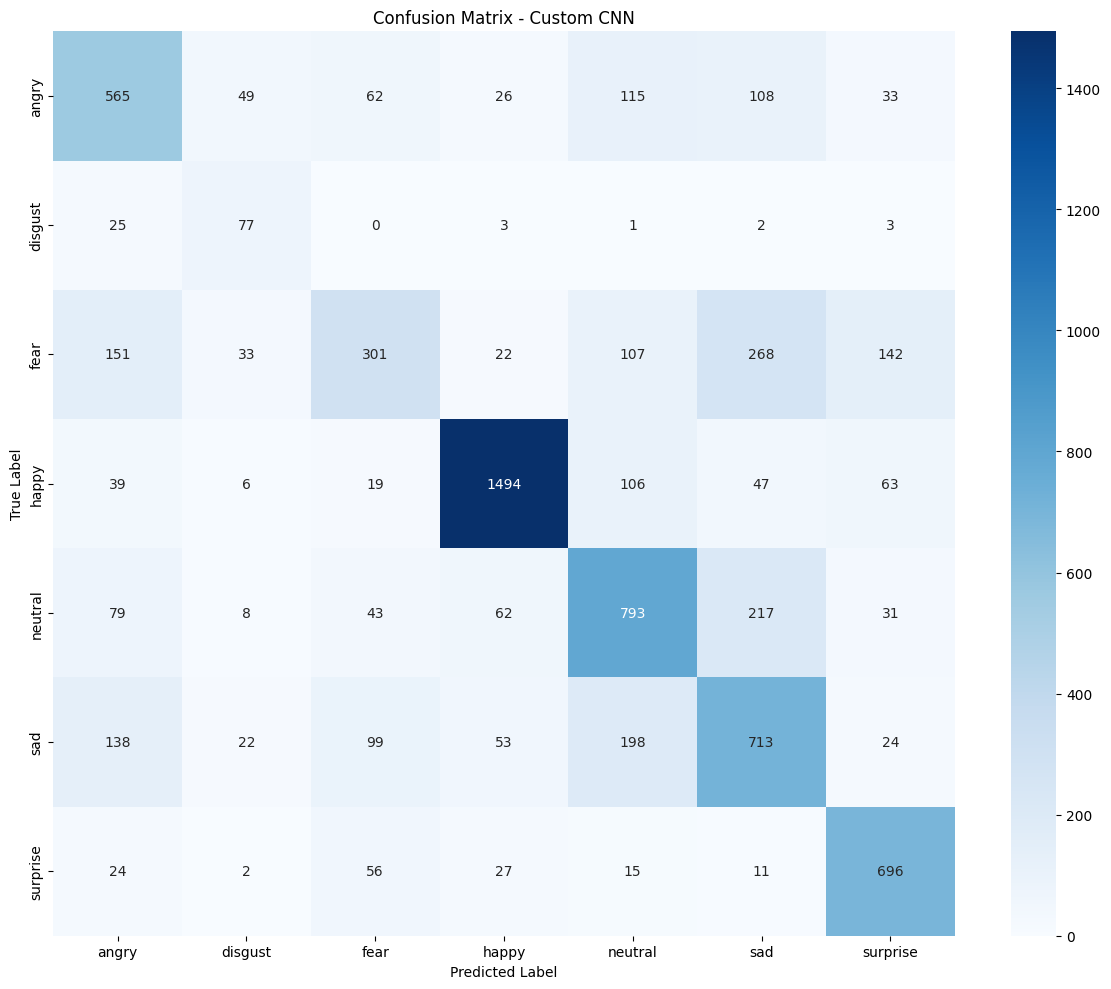


Per-Class Accuracy:
angry: 58.98%
disgust: 69.37%
fear: 29.39%
happy: 84.22%
neutral: 64.31%
sad: 57.18%
surprise: 83.75%


In [12]:
#Section 9: Model Evaluation

def evaluate_model(model, X_test, y_test, class_map, model_name="Model"):
    """Comprehensive model evaluation"""
    print(f"\n{'='*70}")
    print(f"EVALUATING {model_name.upper()}")
    print(f"{'='*70}")

    # Predictions
    y_pred_probs = model.predict(X_test, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Overall accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print(f"\nTest Accuracy: {accuracy*100:.2f}%")

    # Classification report
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=list(class_map.keys()),
        digits=4
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm, annot=True, fmt='d',
        xticklabels=list(class_map.keys()),
        yticklabels=list(class_map.keys()),
        cmap='Blues'
    )
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'{model_name.lower().replace(" ", "_")}_confusion_matrix.png', dpi=300)
    plt.show()

    # Per-class accuracy
    print("\nPer-Class Accuracy:")
    class_accuracy = cm.diagonal() / cm.sum(axis=1)
    for idx, emotion in enumerate(class_map.keys()):
        print(f"{emotion}: {class_accuracy[idx]*100:.2f}%")

    return accuracy, y_pred, cm

# Evaluate custom CNN
cnn_accuracy, cnn_predictions, cnn_cm = evaluate_model(
    cnn_model, X_test, y_test, class_map, "Custom CNN"
)

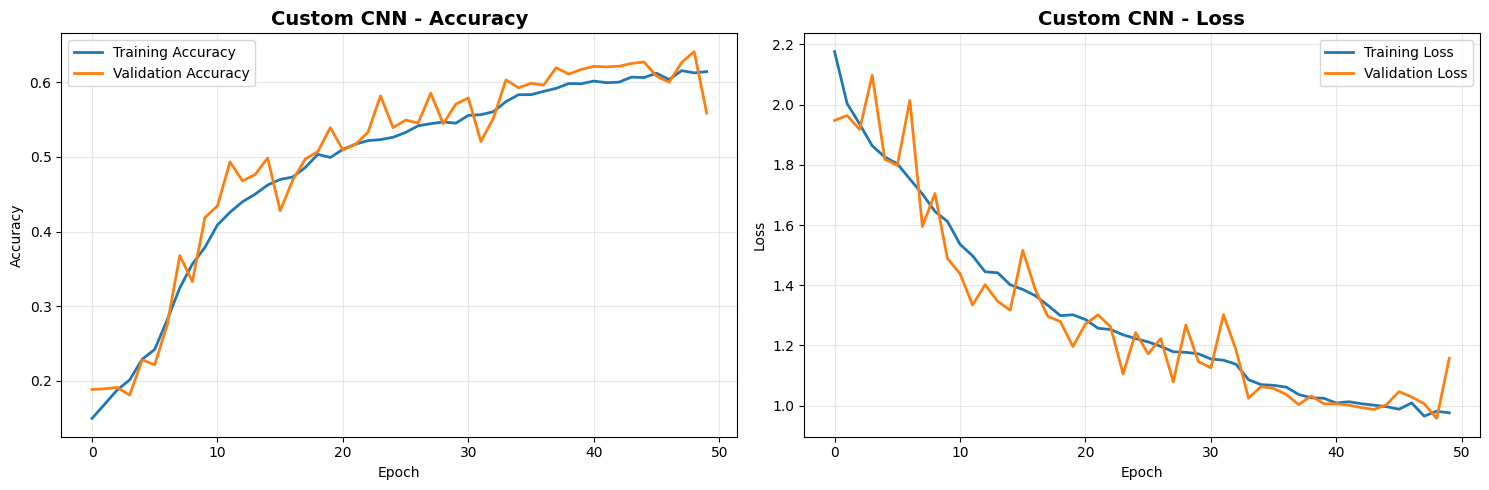

In [13]:
#Section 10: Training Visualization

def plot_training_history(history, model_name="Model"):
    """
    Plot training and validation accuracy/loss curves
    """
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Accuracy plot
    axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
    axes[0].set_title(f'{model_name} - Accuracy', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss plot
    axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
    axes[1].set_title(f'{model_name} - Loss', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{model_name.lower().replace(" ", "_")}_training_history.png', dpi=300)
    plt.show()

# Plot training history
plot_training_history(history_cnn, "Custom CNN")

In [14]:
#Section 11: Comparison with Phase I (Classical Approach)

print("\n" + "="*70)
print("COMPARISON: CLASSICAL (PHASE I) vs DEEP LEARNING (PHASE II)")
print("="*70)

# Phase I results (from your Phase I implementation)
phase1_accuracy = 0.522

comparison_data = {
    'Approach': ['Classical (Phase I)', 'Deep Learning CNN (Phase II)'],
    'Accuracy': [phase1_accuracy, cnn_accuracy],
    'Features': ['HOG + Gabor + Landmarks', 'Learned Features (CNN)'],
    'Training Time': ['Fast (~15 min)', 'Slow (~2-3 hours)'],
    'Interpretability': ['High', 'Low']
}

comparison_df = pd.DataFrame(comparison_data)
print("\n", comparison_df.to_string(index=False))

# Improvement calculation
improvement = (cnn_accuracy - phase1_accuracy) / phase1_accuracy * 100
print(f"\nImprovement over Phase I: {improvement:.2f}%")
print(f"Absolute improvement: {(cnn_accuracy - phase1_accuracy)*100:.2f} percentage points")


COMPARISON: CLASSICAL (PHASE I) vs DEEP LEARNING (PHASE II)

                     Approach  Accuracy                Features     Training Time Interpretability
         Classical (Phase I)   0.52200 HOG + Gabor + Landmarks    Fast (~15 min)             High
Deep Learning CNN (Phase II)   0.64628  Learned Features (CNN) Slow (~2-3 hours)              Low

Improvement over Phase I: 23.81%
Absolute improvement: 12.43 percentage points


In [15]:
#Section 12: Error Analysis

def perform_error_analysis(y_true, y_pred, class_map, top_n=5):
    """Analyze most common misclassifications"""
    print("\n" + "="*70)
    print("ERROR ANALYSIS")
    print("="*70)

    # Find misclassified samples
    misclassified = y_true != y_pred
    misclassified_indices = np.where(misclassified)[0]

    print(f"\nTotal misclassified samples: {len(misclassified_indices)}")
    print(f"Misclassification rate: {len(misclassified_indices)/len(y_true)*100:.2f}%")

    # Most common confusion pairs
    confusion_pairs = {}
    for idx in misclassified_indices:
        true_label = list(class_map.keys())[y_true[idx]]
        pred_label = list(class_map.keys())[y_pred[idx]]
        pair = f"{true_label} → {pred_label}"
        confusion_pairs[pair] = confusion_pairs.get(pair, 0) + 1

    # Sort and display top confusions
    sorted_confusions = sorted(confusion_pairs.items(), key=lambda x: x[1], reverse=True)

    print(f"\nTop {top_n} Most Common Misclassifications:")
    for i, (pair, count) in enumerate(sorted_confusions[:top_n], 1):
        print(f"{i}. {pair}: {count} occurrences ({count/len(misclassified_indices)*100:.2f}%)")

# Perform error analysis
perform_error_analysis(y_test, cnn_predictions, class_map)


ERROR ANALYSIS

Total misclassified samples: 2539
Misclassification rate: 35.37%

Top 5 Most Common Misclassifications:
1. fear → sad: 268 occurrences (10.56%)
2. neutral → sad: 217 occurrences (8.55%)
3. sad → neutral: 198 occurrences (7.80%)
4. fear → angry: 151 occurrences (5.95%)
5. fear → surprise: 142 occurrences (5.59%)


In [18]:
#Section 13: Prediction Function For New Images

def predict_emotion(model, img_path, class_map):
    """Predict emotion from a single image"""

    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(
        img_path,
        color_mode='grayscale',
        target_size=(config.IMG_SIZE, config.IMG_SIZE)
    )
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = model.predict(img_array, verbose=0)
    predicted_class = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class]

    emotion = list(class_map.keys())[predicted_class]

    # Display results
    plt.figure(figsize=(10, 4))

    # Show image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'Predicted: {emotion}\nConfidence: {confidence*100:.2f}%')
    plt.axis('off')

    # Show probability distribution
    plt.subplot(1, 2, 2)
    emotions = list(class_map.keys())
    plt.barh(emotions, predictions[0])
    plt.xlabel('Probability')
    plt.title('Emotion Probabilities')
    plt.xlim(0, 1)

    plt.tight_layout()
    plt.show()

    return emotion, confidence

# Example: Upload and predict (uncomment to use)
from google.colab import files
uploaded = files.upload()
for filename in uploaded.keys():
  emotion, confidence = predict_emotion(cnn_model, filename, class_map)

print(f"Predicted Emotion: {emotion} ({confidence*100:.2f}% confidence)")



In [17]:
#Section 14: Saving Results and Metrics

# Save training history
history_dict = {
    'train_accuracy': history_cnn.history['accuracy'],
    'val_accuracy': history_cnn.history['val_accuracy'],
    'train_loss': history_cnn.history['loss'],
    'val_loss': history_cnn.history['val_loss']
}

history_df = pd.DataFrame(history_dict)
history_df.to_csv('training_history.csv', index=False)

# Save evaluation metrics
metrics_dict = {
    'Model': ['Custom CNN'],
    'Test Accuracy': [cnn_accuracy],
    'Number of Parameters': [cnn_model.count_params()],
    'Training Epochs': [len(history_cnn.history['accuracy'])]
}

metrics_df = pd.DataFrame(metrics_dict)
metrics_df.to_csv('model_metrics.csv', index=False)

print("\n" + "="*70)
print("PHASE II IMPLEMENTATION COMPLETED SUCCESSFULLY!")
print("="*70)
print("\nFiles saved:")
print("- best_model.h5 (best model during training)")
print("- custom_cnn_final.h5 (final model)")
print("- training_history.csv (training metrics)")
print("- model_metrics.csv (evaluation metrics)")
print("- confusion_matrix.png (visualization)")
print("- training_history.png (visualization)")


PHASE II IMPLEMENTATION COMPLETED SUCCESSFULLY!

Files saved:
- best_model.h5 (best model during training)
- custom_cnn_final.h5 (final model)
- training_history.csv (training metrics)
- model_metrics.csv (evaluation metrics)
- confusion_matrix.png (visualization)
- training_history.png (visualization)
